# Reference images v2: segmented object -> style-only IP-Adapter -> filtered candidates

What changed versus v1 (and why):

| v1 problem | v2 fix |
|---|---|
| Whole photo went into the adapter, so backgrounds (floral paper, fence, leaves) leaked into the reference | **Stage A1:** segment the target object (CLIPSeg with the Sketchy category as the text prompt, refined by SAM) and paste it on **neutral gray** |
| Random categories (hammer -> swan, bench -> eyeglasses) made hybrids | **Neutral objects** (vase, mug, ball, bottle, box, bowl) that are never the target's own category |
| Prompt said nothing about appearance | **Stage A2:** Qwen3-VL extracts `colors / material / finish` from the segmented object and puts them in the prompt |
| Filter only checked "looks different" (DINO), so weird images passed | **Stage B:** up to `N_CAND` candidates per photo, scored on DINO (geometry must differ), **Lab colour-histogram distance** (appearance must match), and a **plain-background / isolated-object check** |

Pipeline order (each stage is resumable and saves to Drive):
`A1 segment -> A2 attributes -> B generate + filter -> review -> retry failures`

**Look at the segmentation preview (end of A1) before moving on.** If masks are bad, everything downstream is bad.

Needs a GPU runtime (T4 is fine). Input: `sketchy_captions_sample.csv` (needs `category` and `image_path` columns).

**Drive quota safe:** all work happens on Colab's local disk (`/content/ref_v2`). Progress is saved to Drive only as one zip (`ref_v2_backup.zip`) at the end of each stage and every 50 images. After a disconnect, just re-run the cells: the zip is restored automatically and the stages resume. Colab's local disk is wiped on disconnect, so do not skip the backups.

In [1]:
!pip install -q -U diffusers transformers accelerate opencv-python-headless scipy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 69.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 74.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 16.7 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os, re, gc, io, time, shutil, base64, torch, numpy as np, pandas as pd
import torch.nn.functional as F
import scipy.ndimage as ndi
import cv2
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import HTML, display

# ---------------- CONFIG ----------------
ROOT      = '/content/drive/MyDrive/sketchy_dataset_one_sketch'
CSV_IN    = os.path.join(ROOT, 'sketchy_captions_sample.csv')
WORK      = '/content/ref_v2'                                 # LOCAL Colab disk (fast, no Drive quota); backed up as one zip
LOCAL_DATA = '/content/local_data'                            # local copies of the input photos
BACKUP_ZIP = os.path.join(ROOT, 'ref_v2_backup.zip')          # the only thing written to Drive
INPUT_DIR = os.path.join(WORK, 'object_inputs')               # segmented object on gray (adapter input)
MASK_DIR  = os.path.join(WORK, 'object_masks')
REF_DIR   = os.path.join(WORK, 'reference_images')
STAGE_CSV = os.path.join(WORK, 'stage_inputs.csv')            # after A1 + A2
RES_CSV   = os.path.join(WORK, 'stage_results.csv')           # after B (resumable)
CSV_OUT   = os.path.join(WORK, 'sketchy_with_refs_v2.csv')    # final merged table (also inside the backup zip)
for d in [WORK, LOCAL_DATA, INPUT_DIR, MASK_DIR, REF_DIR]:
    os.makedirs(d, exist_ok=True)

# --- segmentation (A1)
INPUT_SIZE       = 512     # side of the gray-background object image fed to the adapter
CLIPSEG_REL      = 0.5     # keep pixels above REL * max-prob ...
CLIPSEG_MIN      = 0.2     # ... but never below this absolute prob
USE_SAM          = True    # refine the CLIPSeg box with SAM (falls back to CLIPSeg mask if SAM looks wrong)
MIN_MASK_FRAC    = 0.01    # mask smaller than this fraction of the photo = segmentation failed
MAX_MASK_FRAC    = 0.90    # mask larger than this = segmentation failed (whole image)

# --- attributes (A2)
VLM_ID = 'Qwen/Qwen3-VL-2B-Instruct'
VLM_DTYPE = torch.float16  # if the attribute text comes out as garbage on a T4, switch to torch.float32

# --- generation (B)
SDXL_ID      = 'stabilityai/stable-diffusion-xl-base-1.0'
RES, STEPS, CFG = 768, 25, 6.5
STYLE_SCALE  = 1.0         # strength of the style-only adapter block (try 0.6-1.0)
N_CAND       = 3           # candidates per photo (each uses a different neutral object)
EARLY_ACCEPT = True        # stop at the first candidate that passes all checks (saves a lot of time)
NEUTRAL_OBJECTS = ['vase', 'mug', 'ball', 'bottle', 'box', 'bowl']
NEG = ('multiple objects, several objects, collage, grid, set, pair, duplicates, multiple views, contact sheet, frame, border, '
       'cluttered background, scene, people, text, watermark, deformed, blurry, low quality')
SEED = 0

# --- filters (tune after looking at the stats printed in the review cell)
DINO_MAX   = 0.28          # DINOv2 cosine to the target: ABOVE this = geometry/semantics leaked
COLOR_MAX  = 0.55          # Lab-histogram Hellinger distance: ABOVE this = appearance did not transfer
FG_RANGE   = (0.05, 0.85)  # fraction of the candidate covered by the object (rejects empty / scene-filling images)
BG_STD_MAX = 40.0          # border-pixel std: ABOVE this = background is not plain
# ----------------------------------------

df = pd.read_csv(CSV_IN).reset_index(drop=True)
print(len(df), 'rows | columns:', list(df.columns))
assert {'category', 'image_path'} <= set(df.columns), 'CSV needs category and image_path columns'

# ---- backup / restore (one zip on Drive instead of hundreds of small files)
def backup():
    try:
        shutil.make_archive('/content/ref_v2_backup', 'zip', WORK)
        shutil.copy('/content/ref_v2_backup.zip', BACKUP_ZIP)
        print('backup saved ->', BACKUP_ZIP)
    except Exception as e:
        print('backup to Drive failed (will retry next time):', repr(e)[:120])

if os.path.exists(BACKUP_ZIP) and not os.listdir(INPUT_DIR):
    shutil.unpack_archive(BACKUP_ZIP, WORK)
    print('restored previous progress from', BACKUP_ZIP)

# ---- copy the input photos from Drive to local disk once (with retries for Drive hiccups)
def to_local(p, cat):
    d = os.path.join(LOCAL_DATA, str(cat)); os.makedirs(d, exist_ok=True)
    dst = os.path.join(d, os.path.basename(p))
    if os.path.exists(dst) and os.path.getsize(dst) > 0:
        return dst
    for attempt in range(6):
        try:
            shutil.copy(p, dst)
            return dst
        except OSError as e:
            print('Drive read failed, waiting...', repr(e)[:80])
            time.sleep(15 * (attempt + 1))
    raise RuntimeError('could not copy ' + p + ' from Drive; try again later')

df['image_path'] = [to_local(p, c) for p, c in tqdm(list(zip(df.image_path, df.category)))]
print('photos are now local')

200 rows | columns: ['category', 'image_path', 'sketch_path', 'caption']
restored previous progress from /content/drive/MyDrive/sketchy_dataset_one_sketch/ref_v2_backup.zip


  0%|          | 0/200 [00:00<?, ?it/s]

photos are now local


## Helper functions (no models needed)

In [4]:
def cat_name(c):
    return str(c).replace('_', ' ').replace('-', ' ')

def keep_big_components(m, frac=0.25):
    # keep the largest connected component plus any other component >= frac * largest, then fill holes
    lab, n = ndi.label(m)
    if n == 0:
        return m
    sizes = np.array(ndi.sum(m, lab, range(1, n + 1)))
    keep = [i + 1 for i, s in enumerate(sizes) if s >= frac * sizes.max()]
    return ndi.binary_fill_holes(np.isin(lab, keep))

def mask_box(mask, margin=0.05):
    ys, xs = np.where(mask)
    H, W = mask.shape
    x0, x1, y0, y1 = xs.min(), xs.max() + 1, ys.min(), ys.max() + 1
    mx, my = int((x1 - x0) * margin), int((y1 - y0) * margin)
    return [int(max(0, x0 - mx)), int(max(0, y0 - my)), int(min(W, x1 + mx)), int(min(H, y1 + my))]

def compose_object(img, mask, box, out=INPUT_SIZE):
    # paste the masked object on neutral gray, crop to the box, pad to a square
    arr = np.asarray(img.convert('RGB')).astype(np.float32)
    m = ndi.binary_erosion(mask, iterations=2) if mask.sum() > 4000 else mask   # trim background halo
    alpha = ndi.gaussian_filter(m.astype(np.float32), 1.0)[..., None]
    canvas = arr * alpha + 128.0 * (1 - alpha)
    x0, y0, x1, y1 = box
    crop = canvas[y0:y1, x0:x1]
    h, w = crop.shape[:2]
    s = max(h, w)
    sq = np.full((s, s, 3), 128.0, np.float32)
    oy, ox = (s - h) // 2, (s - w) // 2
    sq[oy:oy + h, ox:ox + w] = crop
    return Image.fromarray(sq.clip(0, 255).astype(np.uint8)).resize((out, out), Image.LANCZOS)

def lab_hist(rgb_arr, mask):
    # smoothed 8x8x8 CIE-Lab histogram of the pixels inside the mask
    lab = cv2.cvtColor(np.ascontiguousarray(rgb_arr.astype(np.uint8)), cv2.COLOR_RGB2LAB)
    px = lab[mask]
    if len(px) < 50:
        return None
    h, _ = np.histogramdd(px.astype(np.float32), bins=(8, 8, 8), range=((0, 256),) * 3)
    h = ndi.gaussian_filter(h, 1.0)
    return h / h.sum()

def color_dist(h1, h2):
    # Hellinger distance in [0, 1]; 0 = identical colour distribution
    if h1 is None or h2 is None:
        return 1.0
    return float(np.sqrt(max(0.0, 1.0 - np.sum(np.sqrt(h1 * h2)))))

def candidate_fg(arr):
    # object mask for a generated candidate on a (hopefully) plain background + background plainness
    a = arr.astype(np.float32)
    border = np.concatenate([a[:8].reshape(-1, 3), a[-8:].reshape(-1, 3),
                             a[:, :8].reshape(-1, 3), a[:, -8:].reshape(-1, 3)])
    bg_std = float(border.std(0).mean())
    # per-row and per-column background models, so studio gradients are not mistaken for objects
    bg_r = np.median(np.concatenate([a[:, :8], a[:, -8:]], axis=1), axis=1)      # (H, 3)
    bg_c = np.median(np.concatenate([a[:8], a[-8:]], axis=0), axis=0)            # (W, 3)
    d = np.minimum(np.linalg.norm(a - bg_r[:, None, :], axis=-1), np.linalg.norm(a - bg_c[None, :, :], axis=-1))
    m = d > 30
    m = ndi.binary_opening(m, iterations=2)
    n_obj = 0
    if m.any():
        lab, n = ndi.label(m)
        sizes = np.array(ndi.sum(m, lab, range(1, n + 1)))
        edge = set(np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]]))) - {0}
        big = [i + 1 for i, sz in enumerate(sizes) if sz >= 0.10 * sizes.max() and sz >= 0.01 * m.size]
        inner = [i for i in big if i not in edge]            # ignore gradient bands / panels touching the border
        n_obj = len(inner) if inner else len(big)
        m = keep_big_components(m)
    return m, bg_std, n_obj

def parse_attrs(text):
    t = text.replace('\n', ' ')
    def g(k):
        m = re.search(k + r'\s*:\s*([^;]+)', t, re.I)
        return m.group(1).strip(' .').lower() if m else ''
    return g('colors?'), g('material'), g('finish')

def _s(x):
    return x.strip() if isinstance(x, str) else ''

def build_prompt(colors, material, finish, obj):
    colors = _s(colors) or 'neutral'
    body = ' '.join(p for p in [_s(finish), _s(material), obj] if p)
    return (f'a single {body} in {colors} colors, one object only, studio product photo, '
            f'isolated on a plain light gray background, centered')

def pick_neutrals(cat, i, n):
    pool = [o for o in NEUTRAL_OBJECTS if o != cat_name(cat)]
    start = (i * 3) % len(pool)                       # rotate per row so objects are spread out
    return [pool[(start + k) % len(pool)] for k in range(n)]

def b64(path, size=200):
    im = Image.open(path).convert('RGB'); im.thumbnail((size, size))
    buf = io.BytesIO(); im.save(buf, format='JPEG', quality=80)
    return base64.b64encode(buf.getvalue()).decode()

## Stage A1: segment the target object and put it on gray
CLIPSeg finds the object from its **category name** (so on the tennis photos it looks for "racket", not "person"). SAM then tightens the mask using CLIPSeg's box. If both fail the size checks, the row falls back to a centre crop and is flagged `seg_ok=False` so you can inspect it.

In [5]:
import torch
from transformers import CLIPSegProcessor, CLIPSegForImageSegmentation
cproc = CLIPSegProcessor.from_pretrained('CIDAS/clipseg-rd64-refined')
cseg = CLIPSegForImageSegmentation.from_pretrained('CIDAS/clipseg-rd64-refined').to('cuda').eval()

sam = sproc = None
if USE_SAM:
    from transformers import SamModel, SamProcessor
    sproc = SamProcessor.from_pretrained('facebook/sam-vit-base')
    sam = SamModel.from_pretrained('facebook/sam-vit-base').to('cuda').eval()

@torch.no_grad()
def clipseg_mask(img, cat):
    W, H = img.size
    inp = cproc(text=[cat_name(cat)], images=[img], padding=True, return_tensors='pt').to('cuda')
    logits = cseg(**inp).logits.float()
    prob = torch.sigmoid(logits).reshape(1, 1, *logits.shape[-2:])
    prob = F.interpolate(prob, size=(H, W), mode='bilinear', align_corners=False)[0, 0].cpu().numpy()
    thr = max(CLIPSEG_MIN, CLIPSEG_REL * float(prob.max()))
    return keep_big_components(prob > thr)

@torch.no_grad()
def sam_mask(img, box):
    inp = sproc(img, input_boxes=[[box]], return_tensors='pt').to('cuda')
    out = sam(**inp, multimask_output=True)
    masks = sproc.image_processor.post_process_masks(
        out.pred_masks.cpu(), inp['original_sizes'].cpu(), inp['reshaped_input_sizes'].cpu())[0][0]
    best = int(out.iou_scores.cpu()[0, 0].argmax())
    return masks[best].numpy().astype(bool)

def segment(img, cat):
    # returns mask, box, method, ok
    H, W = img.size[1], img.size[0]
    m = clipseg_mask(img, cat)
    frac = m.mean()
    if m.any() and MIN_MASK_FRAC <= frac <= MAX_MASK_FRAC:
        box = mask_box(m)
        method = 'clipseg'
        if USE_SAM:
            try:
                sm = keep_big_components(sam_mask(img, box))
                ratio = sm.sum() / max(1, m.sum())
                if sm.any() and 0.4 <= ratio <= 2.0 and MIN_MASK_FRAC <= sm.mean() <= MAX_MASK_FRAC:
                    m, box, method = sm, mask_box(sm), 'clipseg+sam'
            except Exception as e:
                print('SAM failed, using CLIPSeg mask:', repr(e)[:100])
        return m, box, method, True
    # fallback: centre 60% crop, keep everything inside it
    x0, x1, y0, y1 = int(W * .2), int(W * .8), int(H * .2), int(H * .8)
    m = np.zeros((H, W), bool); m[y0:y1, x0:x1] = True
    return m, [x0, y0, x1, y1], 'fallback_center', False

def stem(p):
    return os.path.splitext(os.path.basename(p))[0]

rows = {}
if os.path.exists(STAGE_CSV):
    old = pd.read_csv(STAGE_CSV)
    if 'input_path' in old.columns:
        rows = {int(i): r for i, r in old.to_dict('index').items()}
print('already segmented:', len(rows))

for i, r in tqdm(list(df.iterrows())):
    if i in rows and os.path.exists(rows[i]['input_path']):
        continue
    img = Image.open(r.image_path).convert('RGB')
    m, box, method, ok = segment(img, r.category)
    s = f'{i:04d}_{r.category}_{stem(r.image_path)}'
    ip, mp = os.path.join(INPUT_DIR, s + '.png'), os.path.join(MASK_DIR, s + '.png')
    compose_object(img, m, box).save(ip)
    Image.fromarray((m * 255).astype(np.uint8)).save(mp)
    rows[i] = dict(input_path=ip, mask_path=mp, seg_method=method, seg_ok=ok, mask_frac=round(float(m.mean()), 3))

stage = df.copy()
extra = [c for c in ['input_path', 'mask_path', 'seg_method', 'seg_ok', 'mask_frac', 'attr_raw', 'colors', 'material', 'finish']
         if any(c in r for r in rows.values())]
for col in extra:
    stage[col] = [rows[i].get(col, '') for i in range(len(df))]
stage.to_csv(STAGE_CSV, index=False)
print(stage.seg_method.value_counts().to_string())
print('segmentation failures (seg_ok=False):', int((~stage.seg_ok).sum()))
backup()

preprocessor_config.json:   0%|          | 0.00/380 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.73k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/974 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

already segmented: 200


  0%|          | 0/200 [00:00<?, ?it/s]

seg_method
clipseg+sam        168
fallback_center     26
clipseg              6
segmentation failures (seg_ok=False): 26
backup saved -> /content/drive/MyDrive/sketchy_dataset_one_sketch/ref_v2_backup.zip


0,,,hammerclipseg+sammask_frac 0.062
1,,,racketclipseg+sammask_frac 0.032
2,,,mushroomclipseg+sammask_frac 0.145
3,,,axeclipseg+sammask_frac 0.194
4,,,benchclipseg+sammask_frac 0.091
5,,,racketclipseg+sammask_frac 0.026
6,,,trumpetfallback_centermask_frac 0.357
7,,,lobsterfallback_centermask_frac 0.357
8,,,giraffeclipseg+sammask_frac 0.337
9,,,saxophonefallback_centermask_frac 0.357
10,,,fishclipseg+sammask_frac 0.379

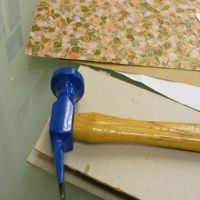
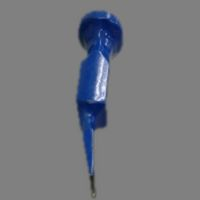
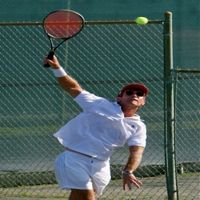
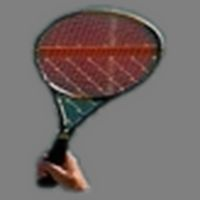
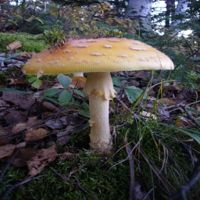
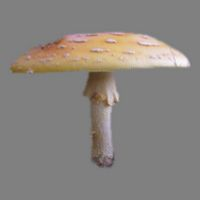
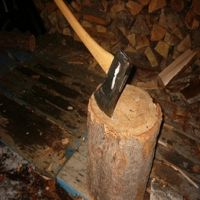
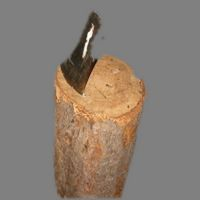
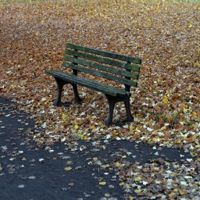
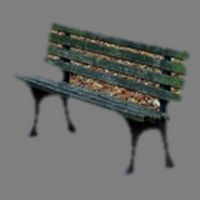
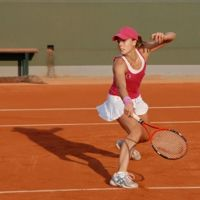
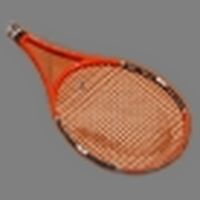
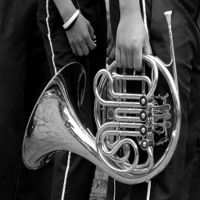
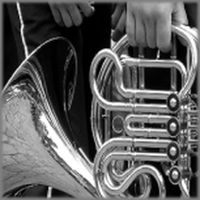
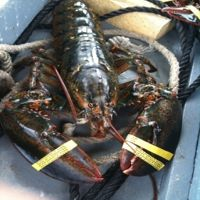
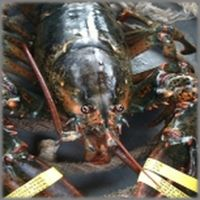
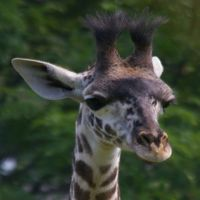
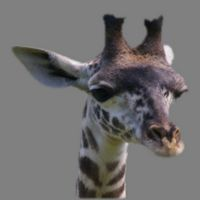
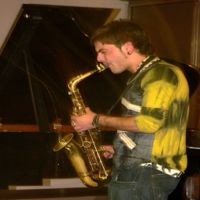
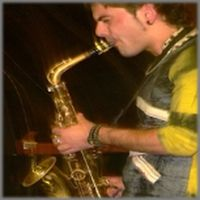
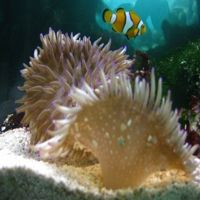
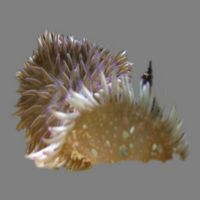
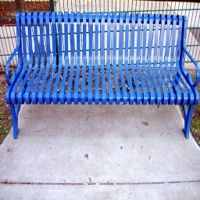
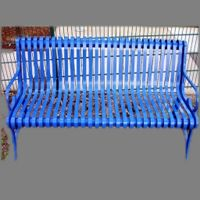

In [6]:
# CHECK THIS BEFORE CONTINUING: target photo | object on gray
def show_inputs(start=0, n=12, only_failed=False):
    sub = stage[~stage.seg_ok] if only_failed else stage.iloc[start:start + n]
    out = ''
    for i, r in sub.head(n).iterrows():
        out += (f"<tr><td style='padding:4px'>{i}</td>"
                f"<td><img src='data:image/jpeg;base64,{b64(r.image_path)}'></td>"
                f"<td><img src='data:image/jpeg;base64,{b64(r.input_path)}'></td>"
                f"<td style='padding:6px'><b>{r.category}</b><br>{r.seg_method}<br>mask_frac {r.mask_frac}</td></tr>")
    display(HTML(f'<table>{out}</table>'))

show_inputs(0, 12)        # then show_inputs(12, 12) ...  or  show_inputs(only_failed=True, n=30)

## Stage A2: extract colour / material / finish with Qwen3-VL
The VLM sees only the segmented object on gray and is told not to name the object or describe its shape, so the prompt carries appearance only.

In [7]:
from transformers import AutoModelForImageTextToText, AutoProcessor

try:
    vlm = AutoModelForImageTextToText.from_pretrained(VLM_ID, dtype=VLM_DTYPE, device_map='cuda')
except TypeError:
    vlm = AutoModelForImageTextToText.from_pretrained(VLM_ID, torch_dtype=VLM_DTYPE, device_map='cuda')
vproc = AutoProcessor.from_pretrained(VLM_ID)
vlm.eval()

ATTR_PROMPT = ('Describe ONLY the surface appearance of the object in this image. Do not name the object '
               'and do not describe its shape. Answer in exactly this format and nothing else: '
               'colors: <up to three colour words>; material: <one or two words, e.g. wood, brushed metal, fur, '
               'glossy plastic, rough stone>; finish: <one or two words, e.g. glossy, matte, rough, smooth, fuzzy>')

@torch.no_grad()
def vlm_attrs(path):
    img = Image.open(path).convert('RGB')
    msgs = [{'role': 'user', 'content': [{'type': 'image', 'image': img}, {'type': 'text', 'text': ATTR_PROMPT}]}]
    inp = vproc.apply_chat_template(msgs, tokenize=True, add_generation_prompt=True,
                                    return_dict=True, return_tensors='pt').to(vlm.device)
    out = vlm.generate(**inp, max_new_tokens=48, do_sample=False)
    return vproc.batch_decode(out[:, inp['input_ids'].shape[1]:], skip_special_tokens=True)[0].strip()

for col in ['attr_raw', 'colors', 'material', 'finish']:
    if col not in stage.columns:
        stage[col] = ''
    stage[col] = stage[col].fillna('').astype(str)

todo = stage.index[stage.attr_raw == '']
for n, i in enumerate(tqdm(todo)):
    raw = vlm_attrs(stage.at[i, 'input_path'])
    c, m, f = parse_attrs(raw)
    stage.at[i, 'attr_raw'] = raw or 'EMPTY'
    stage.at[i, 'colors'], stage.at[i, 'material'], stage.at[i, 'finish'] = c, m, f
    if n % 20 == 0:
        stage.to_csv(STAGE_CSV, index=False)
stage.to_csv(STAGE_CSV, index=False)
backup()
print((stage.colors == '').sum(), 'rows with no parsed colour (will use defaults)')
stage[['category', 'colors', 'material', 'finish']].head(15)

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 4.26GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/625 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

0it [00:00, ?it/s]

backup saved -> /content/drive/MyDrive/sketchy_dataset_one_sketch/ref_v2_backup.zip
3 rows with no parsed colour (will use defaults)


,category,colors,material,finish
0,hammer,blue and white,plastic,glossy
1,racket,"red, black and white",plastic,glossy
2,mushroom,"yellow, orange and white",,matte
3,axe,"brown, tan and grey",wood,rough
4,bench,"green, brown and black",wood,weathered
5,racket,"orange, brown and black",plastic,glossy
6,trumpet,black and white,metal,shiny
7,lobster,green and brown,,rough
8,giraffe,"brown, white and black",skin,smooth
9,saxophone,gold,metal,shiny


### Clean the attributes
The VLM often returns contradictory or non-material words ("glossy, matte", "textured, rough" as a material, "dark" as a colour). This keeps real colour words, the first real material, and the first finish word, so the prompt stays clean.

In [8]:
COLOR_WORDS = {'black','white','gray','grey','silver','gold','golden','brown','tan','beige','red','orange','yellow',
               'green','blue','purple','pink','violet','teal','cyan','maroon','cream','ivory','bronze','copper',
               'brass','navy','turquoise','olive','rust','charcoal'}
COLOR_MODS = {'dark', 'light', 'bright', 'pale', 'deep'}
TEXTURE_WORDS = {'rough','textured','hard','soft','smooth','weathered','painted','worn','shiny','matte',
                 'glossy','reflective','fuzzy','slightly','slightly glossy','polished'}

def clean_attrs(colors, material, finish):
    cols, seen = [], set()
    for chunk in re.split(r',|\band\b', _s(colors).lower()):
        words = [{'rusted': 'rust', 'rusty': 'rust'}.get(w, w) for w in chunk.split()]
        if words and words[-1] in COLOR_WORDS and words[-1] not in seen:
            seen.add(words[-1])
            cols.append(' '.join(w for w in words if w in COLOR_WORDS or w in COLOR_MODS))
    mats = [m.strip() for m in _s(material).lower().split(',') if m.strip()]
    real = [m for m in mats if m not in TEXTURE_WORDS]
    fins = [f.strip() for f in _s(finish).lower().split(',') if f.strip()]
    fins = fins or [m for m in mats if m in TEXTURE_WORDS]
    cols = cols[:3]
    cstr = cols[0] if len(cols) == 1 else (', '.join(cols[:-1]) + ' and ' + cols[-1] if cols else '')
    return cstr, (real[0] if real else ''), (fins[0] if fins else '')

cleaned = [clean_attrs(c, m, f) for c, m, f in zip(stage.colors, stage.material, stage.finish)]
stage['colors'], stage['material'], stage['finish'] = [list(x) for x in zip(*cleaned)]
stage.to_csv(STAGE_CSV, index=False)
backup()
stage[['category', 'colors', 'material', 'finish']].head(15)

backup saved -> /content/drive/MyDrive/sketchy_dataset_one_sketch/ref_v2_backup.zip


,category,colors,material,finish
0,hammer,blue and white,plastic,glossy
1,racket,"red, black and white",plastic,glossy
2,mushroom,"yellow, orange and white",,matte
3,axe,"brown, tan and grey",wood,rough
4,bench,"green, brown and black",wood,weathered
5,racket,"orange, brown and black",plastic,glossy
6,trumpet,black and white,metal,shiny
7,lobster,green and brown,,rough
8,giraffe,"brown, white and black",skin,smooth
9,saxophone,gold,metal,shiny


In [9]:
# free the stage-A models before loading SDXL
for n in ['cseg', 'cproc', 'sam', 'sproc', 'vlm', 'vproc']:
    globals().pop(n, None)
gc.collect(); torch.cuda.empty_cache()
print('VRAM in use (GB):', round(torch.cuda.memory_allocated() / 1e9, 2))

VRAM in use (GB): 0.0


## Stage B: SDXL + IP-Adapter (style-only), candidates, filtering

In [10]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [11]:
import torch
from diffusers import AutoPipelineForText2Image, AutoencoderKL
from transformers import CLIPVisionModelWithProjection, AutoModel, AutoImageProcessor

image_encoder = CLIPVisionModelWithProjection.from_pretrained(
    'h94/IP-Adapter', subfolder='models/image_encoder', torch_dtype=torch.float16).to('cuda')
vae = AutoencoderKL.from_pretrained('madebyollin/sdxl-vae-fp16-fix', torch_dtype=torch.float16).to('cuda')
kw = dict(torch_dtype=torch.float16, variant='fp16', use_safetensors=True, vae=vae, image_encoder=image_encoder)
try:
    pipe = AutoPipelineForText2Image.from_pretrained(SDXL_ID, device_map='cuda', **kw)
except Exception as e:
    print('device_map not supported, falling back:', repr(e)[:120])
    gc.collect(); torch.cuda.empty_cache()
    pipe = AutoPipelineForText2Image.from_pretrained(SDXL_ID, **kw).to('cuda')
pipe.load_ip_adapter('h94/IP-Adapter', subfolder='sdxl_models', weight_name='ip-adapter_sdxl_vit-h.bin')
pipe.set_progress_bar_config(disable=True)
pipe.set_ip_adapter_scale({'up': {'block_0': [0.0, STYLE_SCALE, 0.0]}})   # style-only block

dproc = AutoImageProcessor.from_pretrained('facebook/dinov2-small')
dino = AutoModel.from_pretrained('facebook/dinov2-small').to('cuda').eval()
print('VRAM used (GB):', round(torch.cuda.memory_allocated() / 1e9, 1))

config.json:   0%|          | 0.00/560 [00:00<?, ?B/s]

models/image_encoder/model.safetensors: reconstructing file:   0%|          |  0.00B / 2.53GB            

models/image_encoder/model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/520 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


...

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

VRAM used (GB): 9.0


In [12]:
@torch.no_grad()
def dino_emb(im):
    x = dproc(images=im.convert('RGB'), return_tensors='pt').to('cuda')
    return F.normalize(dino(**x).last_hidden_state[:, 0], dim=-1)[0]

@torch.no_grad()
def gen(prompt, ip_img, seed):
    return pipe(prompt=prompt, negative_prompt=NEG, ip_adapter_image=ip_img,
                num_inference_steps=STEPS, guidance_scale=CFG, height=RES, width=RES,
                generator=torch.Generator('cuda').manual_seed(int(seed))).images[0]

def score_candidate(cand, t_hist, t_embs):
    arr = np.asarray(cand.convert('RGB'))
    fg, bg_std, n_obj = candidate_fg(arr)
    fg_frac = float(fg.mean())
    c_hist = lab_hist(arr, fg) if fg_frac >= 0.01 else None
    cd = color_dist(t_hist, c_hist)
    e = dino_emb(cand)
    dsim = max(float(e @ t) for t in t_embs)                 # vs original photo AND vs segmented object
    passed = (dsim <= DINO_MAX and cd <= COLOR_MAX and bg_std <= BG_STD_MAX
              and FG_RANGE[0] <= fg_frac <= FG_RANGE[1] and n_obj == 1)
    return dict(dino_sim=round(dsim, 3), color_dist=round(cd, 3), fg_frac=round(fg_frac, 3),
                bg_std=round(bg_std, 1), n_obj=int(n_obj), passed=bool(passed), score=cd + max(dsim, 0.0))

def process_row(i, r, n_cand=N_CAND, seed_offset=0):
    tgt = Image.open(r.image_path).convert('RGB')
    inp = Image.open(r.input_path).convert('RGB')
    mask = np.asarray(Image.open(r.mask_path)) > 127
    t_hist = lab_hist(np.asarray(tgt), mask)
    t_embs = [dino_emb(tgt), dino_emb(inp)]
    best, tries = None, 0
    for k, obj in enumerate(pick_neutrals(r.category, i, n_cand)):
        prompt = build_prompt(r.colors, r.material, r.finish, obj)
        cand = gen(prompt, inp, SEED + seed_offset + 100 * i + k)
        m = score_candidate(cand, t_hist, t_embs)
        m.update(prompt=prompt, ref_object=obj)
        tries += 1
        if best is None or (not m['passed'], m['score']) < (not best[1]['passed'], best[1]['score']):
            best = (cand, m)
        if m['passed'] and EARLY_ACCEPT:
            break
    cand, m = best
    d = os.path.join(REF_DIR, r.category); os.makedirs(d, exist_ok=True)
    ref_path = os.path.join(d, f'{stem(r.image_path)}_ref.png')
    cand.save(ref_path)
    m.update(ref_path=ref_path, n_tries=tries)
    m.pop('score', None)
    return m

results = {}
if os.path.exists(RES_CSV):
    results = {int(i): r for i, r in pd.read_csv(RES_CSV, index_col='row').to_dict('index').items()}
print('already done:', len(results))

def save_results():
    pd.DataFrame.from_dict(results, orient='index').sort_index().to_csv(RES_CSV, index_label='row')

def show(frame, start=0, n=10):
    out = ''
    for i, r in frame.iloc[start:start + n].iterrows():
        out += (f"<tr><td style='padding:4px'>{i}</td>"
                f"<td><img src='data:image/jpeg;base64,{b64(r.image_path)}'></td>"
                f"<td><img src='data:image/jpeg;base64,{b64(r.input_path)}'></td>"
                f"<td><img src='data:image/jpeg;base64,{b64(r.ref_path)}'></td>"
                f"<td style='padding:6px;font-size:13px'><b>target:</b> {r.category} | <b>ref obj:</b> {r.ref_object}<br>"
                f"dino {r.dino_sim} | colour_dist {r.color_dist} | fg {r.fg_frac} | bg_std {r.bg_std} | objects {r.n_obj}<br>"
                f"<b>{'PASS' if r.passed else 'FAIL'}</b> after {r.n_tries} tries<br>"
                f"<i>{r.prompt}</i></td></tr>")
    display(HTML(f'<table>{out}</table>'))

already done: 0


0,,,,"target: hammer | ref obj: vasedino 0.209 | colour_dist 0.119 | fg 0.262 | bg_std 2.2 | objects 1PASS after 1 triesa single glossy plastic vase in blue and white colors, one object only, studio product photo, isolated on a plain light gray background, centered"
1,,,,"target: racket | ref obj: bottledino 0.234 | colour_dist 0.214 | fg 0.18 | bg_std 2.8 | objects 1PASS after 1 triesa single glossy plastic bottle in red, black and white colors, one object only, studio product photo, isolated on a plain light gray background, centered"
2,,,,"target: mushroom | ref obj: vasedino 0.064 | colour_dist 0.14 | fg 0.206 | bg_std 0.7 | objects 1PASS after 1 triesa single matte vase in yellow, orange and white colors, one object only, studio product photo, isolated on a plain light gray background, centered"
3,,,,"target: axe | ref obj: boxdino 0.268 | colour_dist 0.354 | fg 0.387 | bg_std 2.6 | objects 1PASS after 2 triesa single rough wood box in brown, tan and grey colors, one object only, studio product photo, isolated on a plain light gray background, centered"
4,,,,"target: bench | ref obj: vasedino 0.172 | colour_dist 0.158 | fg 0.137 | bg_std 2.7 | objects 1PASS after 1 triesa single weathered wood vase in green, brown and black colors, one object only, studio product photo, isolated on a plain light gray background, centered"
5,,,,"target: racket | ref obj: boxdino 0.189 | colour_dist 0.094 | fg 0.325 | bg_std 0.9 | objects 1PASS after 2 triesa single glossy plastic box in orange, brown and black colors, one object only, studio product photo, isolated on a plain light gray background, centered"

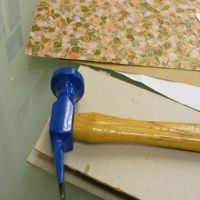
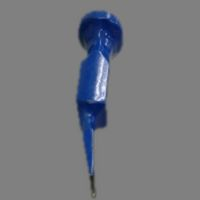
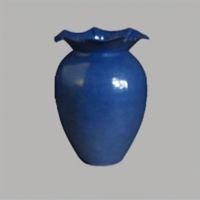
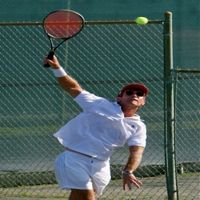
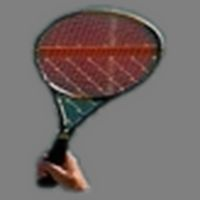
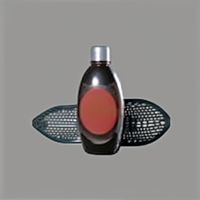
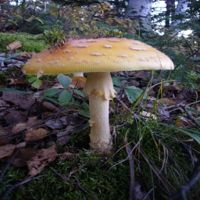
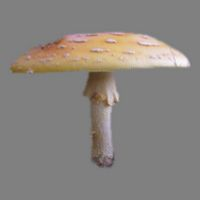
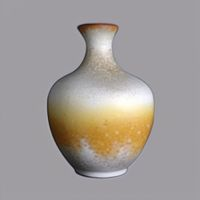
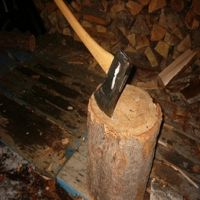
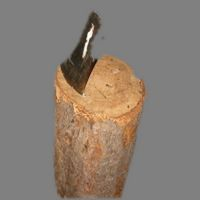
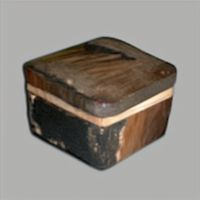
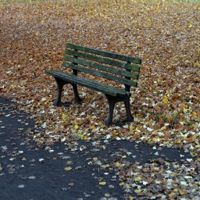
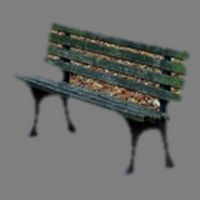
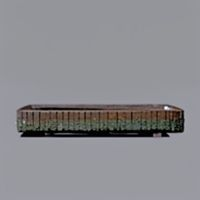
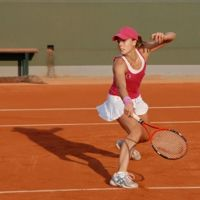
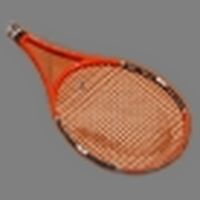
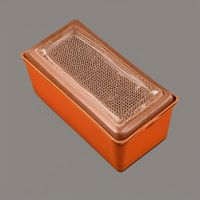

In [13]:
# quick test on the first 6 rows: look at these before the full run, tune STYLE_SCALE / thresholds if needed
for i in range(6):
    results[i] = process_row(i, stage.iloc[i])
save_results()
test = stage.join(pd.DataFrame.from_dict(results, orient='index'), how='inner')
show(test, 0, 6)

In [14]:
# full run (resumable: re-run this cell after a Colab disconnect and it picks up where it stopped)
for i, r in tqdm(list(stage.iterrows())):
    if i in results and os.path.exists(results[i]['ref_path']):
        continue
    results[i] = process_row(i, r)
    if len(results) % 10 == 0:
        save_results()
    if len(results) % 50 == 0:
        backup()
save_results()
backup()
print('done')

  0%|          | 0/200 [00:00<?, ?it/s]

backup saved -> /content/drive/MyDrive/sketchy_dataset_one_sketch/ref_v2_backup.zip
backup saved -> /content/drive/MyDrive/sketchy_dataset_one_sketch/ref_v2_backup.zip
backup saved -> /content/drive/MyDrive/sketchy_dataset_one_sketch/ref_v2_backup.zip
backup saved -> /content/drive/MyDrive/sketchy_dataset_one_sketch/ref_v2_backup.zip
backup saved -> /content/drive/MyDrive/sketchy_dataset_one_sketch/ref_v2_backup.zip
done


## Review
Look at the distributions first: if almost everything fails one check, the threshold (not the images) is probably the problem. Move `DINO_MAX` / `COLOR_MAX` and re-score, or retry the failures below.

       dino_sim  color_dist  fg_frac   bg_std  n_tries
count   200.000     200.000  200.000  200.000  200.000
mean      0.181       0.213    0.253    8.676    1.790
std       0.102       0.090    0.132   11.212    0.877
min      -0.033       0.056    0.064    0.500    1.000
25%       0.106       0.144    0.163    1.000    1.000
50%       0.175       0.200    0.218    2.300    1.000
75%       0.250       0.266    0.307   15.200    3.000
max       0.577       0.496    0.813   56.000    3.000

passed: 154 / 200
fail reasons -> dino: 28 | colour: 0 | bg: 3 | fg: 0 | multi-object: 20
failed rows also with bad segmentation: 5


0,,,,"target: hammer | ref obj: vasedino 0.209 | colour_dist 0.119 | fg 0.262 | bg_std 2.2 | objects 1PASS after 1 triesa single glossy plastic vase in blue and white colors, one object only, studio product photo, isolated on a plain light gray background, centered"
1,,,,"target: racket | ref obj: bottledino 0.234 | colour_dist 0.214 | fg 0.18 | bg_std 2.8 | objects 1PASS after 1 triesa single glossy plastic bottle in red, black and white colors, one object only, studio product photo, isolated on a plain light gray background, centered"
2,,,,"target: mushroom | ref obj: vasedino 0.064 | colour_dist 0.14 | fg 0.206 | bg_std 0.7 | objects 1PASS after 1 triesa single matte vase in yellow, orange and white colors, one object only, studio product photo, isolated on a plain light gray background, centered"
3,,,,"target: axe | ref obj: boxdino 0.268 | colour_dist 0.354 | fg 0.387 | bg_std 2.6 | objects 1PASS after 2 triesa single rough wood box in brown, tan and grey colors, one object only, studio product photo, isolated on a plain light gray background, centered"
4,,,,"target: bench | ref obj: vasedino 0.172 | colour_dist 0.158 | fg 0.137 | bg_std 2.7 | objects 1PASS after 1 triesa single weathered wood vase in green, brown and black colors, one object only, studio product photo, isolated on a plain light gray background, centered"
5,,,,"target: racket | ref obj: boxdino 0.189 | colour_dist 0.094 | fg 0.325 | bg_std 0.9 | objects 1PASS after 2 triesa single glossy plastic box in orange, brown and black colors, one object only, studio product photo, isolated on a plain light gray background, centered"
6,,,,"target: trumpet | ref obj: balldino 0.065 | colour_dist 0.157 | fg 0.551 | bg_std 15.2 | objects 2FAIL after 3 triesa single shiny metal ball in black and white colors, one object only, studio product photo, isolated on a plain light gray background, centered"
7,,,,"target: lobster | ref obj: bottledino 0.03 | colour_dist 0.213 | fg 0.537 | bg_std 22.1 | objects 1PASS after 1 triesa single rough bottle in green and brown colors, one object only, studio product photo, isolated on a plain light gray background, centered"
8,,,,"target: giraffe | ref obj: vasedino 0.227 | colour_dist 0.211 | fg 0.172 | bg_std 2.6 | objects 1PASS after 1 triesa single smooth skin vase in brown, white and black colors, one object only, studio product photo, isolated on a plain light gray background, centered"
9,,,,"target: saxophone | ref obj: boxdino 0.117 | colour_dist 0.344 | fg 0.265 | bg_std 22.4 | objects 1PASS after 2 triesa single shiny metal box in gold colors, one object only, studio product photo, isolated on a plain light gray background, centered"
10,,,,"target: fish | ref obj: mugdino 0.423 | colour_dist 0.189 | fg 0.205 | bg_std 1.3 | objects 1FAIL after 3 triesa single fuzzy mug in brown, beige and white colors, one object only, studio product photo, isolated on a plain light gray background, centered"

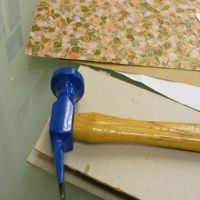
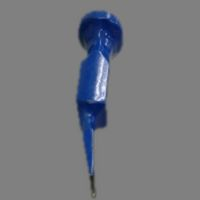
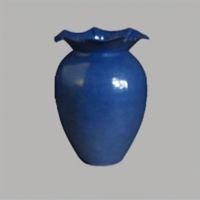
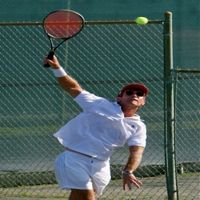
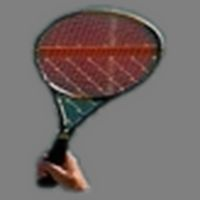
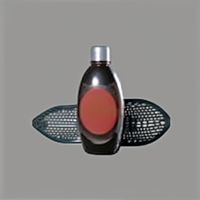
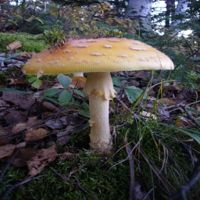
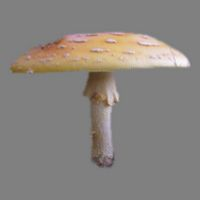
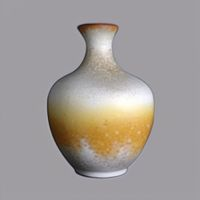
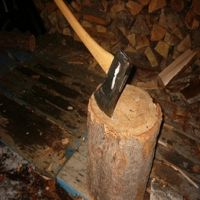
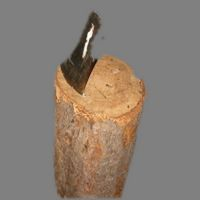
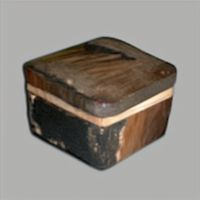
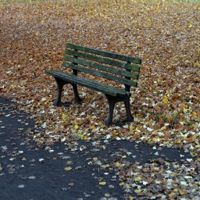
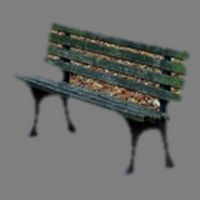
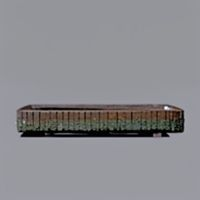
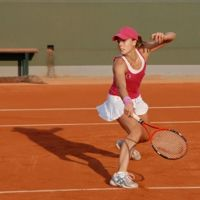
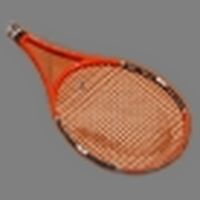
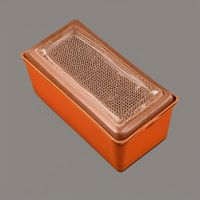
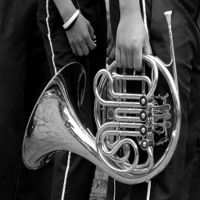
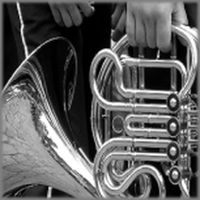
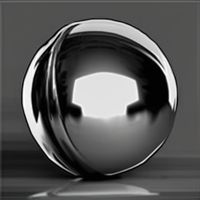
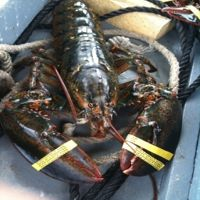
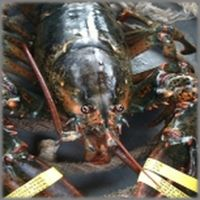
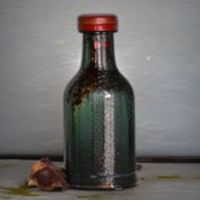
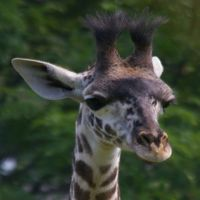
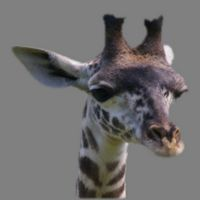
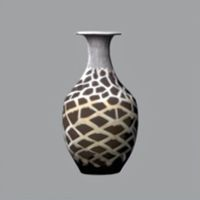
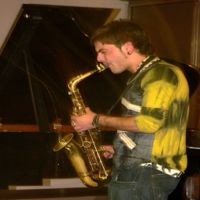
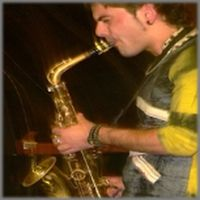
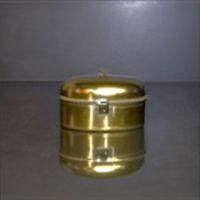
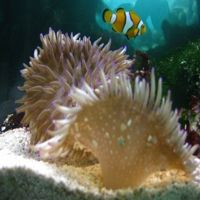
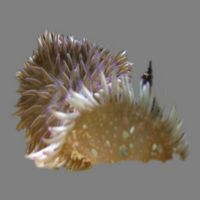
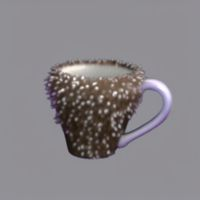
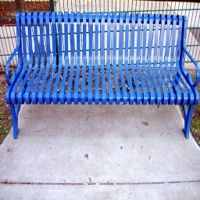
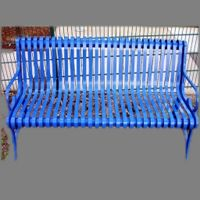
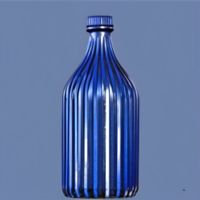

In [15]:
res = pd.DataFrame.from_dict(results, orient='index').sort_index()
full = stage.join(res, how='inner')
print(full[['dino_sim', 'color_dist', 'fg_frac', 'bg_std', 'n_tries']].describe().round(3).to_string())
print('\npassed:', int(full.passed.sum()), '/', len(full))
print('fail reasons ->',
      'dino:', int((full.dino_sim > DINO_MAX).sum()),
      '| colour:', int((full.color_dist > COLOR_MAX).sum()),
      '| bg:', int((full.bg_std > BG_STD_MAX).sum()),
      '| fg:', int(((full.fg_frac < FG_RANGE[0]) | (full.fg_frac > FG_RANGE[1])).sum()),
      '| multi-object:', int((full.n_obj != 1).sum()))
print('failed rows also with bad segmentation:', int(((~full.passed) & (~full.seg_ok)).sum()))
show(full, 0, 12)    # then show(full, 12, 12), ...

6,,,,"target: trumpet | ref obj: balldino 0.065 | colour_dist 0.157 | fg 0.551 | bg_std 15.2 | objects 2FAIL after 3 triesa single shiny metal ball in black and white colors, one object only, studio product photo, isolated on a plain light gray background, centered"
10,,,,"target: fish | ref obj: mugdino 0.423 | colour_dist 0.189 | fg 0.205 | bg_std 1.3 | objects 1FAIL after 3 triesa single fuzzy mug in brown, beige and white colors, one object only, studio product photo, isolated on a plain light gray background, centered"
16,,,,"target: strawberry | ref obj: mugdino 0.317 | colour_dist 0.193 | fg 0.23 | bg_std 1.1 | objects 1FAIL after 3 triesa single smooth fruit mug in red, pink and orange colors, one object only, studio product photo, isolated on a plain light gray background, centered"
18,,,,"target: sheep | ref obj: vasedino 0.16 | colour_dist 0.137 | fg 0.358 | bg_std 52.6 | objects 1FAIL after 3 triesa single fuzzy wool vase in white, black and pink colors, one object only, studio product photo, isolated on a plain light gray background, centered"
22,,,,"target: mushroom | ref obj: mugdino 0.316 | colour_dist 0.214 | fg 0.261 | bg_std 24.2 | objects 1FAIL after 3 triesa single glossy plastic mug in red and white colors, one object only, studio product photo, isolated on a plain light gray background, centered"
23,,,,"target: harp | ref obj: bottledino 0.13 | colour_dist 0.205 | fg 0.176 | bg_std 0.7 | objects 7FAIL after 3 triesa single glossy wood bottle in red, gold and brown colors, one object only, studio product photo, isolated on a plain light gray background, centered"
25,,,,"target: horse | ref obj: boxdino 0.029 | colour_dist 0.129 | fg 0.236 | bg_std 0.8 | objects 4FAIL after 3 triesa single matte leather box in black, white and brown colors, one object only, studio product photo, isolated on a plain light gray background, centered"
28,,,,"target: rhinoceros | ref obj: mugdino 0.071 | colour_dist 0.225 | fg 0.194 | bg_std 0.7 | objects 3FAIL after 3 triesa single matte thick mug in light grey and white colors, one object only, studio product photo, isolated on a plain light gray background, centered"
30,,,,"target: chair | ref obj: vasedino 0.294 | colour_dist 0.255 | fg 0.162 | bg_std 6.3 | objects 1FAIL after 3 triesa single matte wood vase in dark brown and grey colors, one object only, studio product photo, isolated on a plain light gray background, centered"
31,,,,"target: umbrella | ref obj: bottledino 0.311 | colour_dist 0.218 | fg 0.175 | bg_std 3.8 | objects 1FAIL after 3 triesa single textured fabric bottle in black, white and grey colors, one object only, studio product photo, isolated on a plain light gray background, centered"
41,,,,"target: seagull | ref obj: bottledino 0.121 | colour_dist 0.113 | fg 0.152 | bg_std 2.2 | objects 3FAIL after 3 triesa single matte feathered bottle in white, grey and yellow colors, one object only, studio product photo, isolated on a plain light gray background, centered"

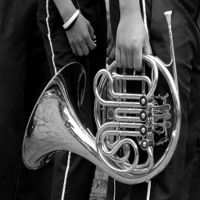
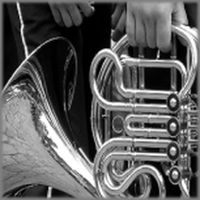
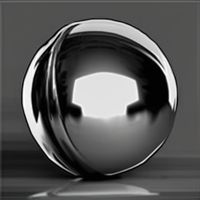
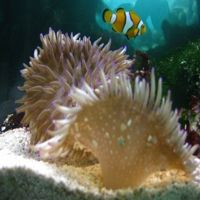
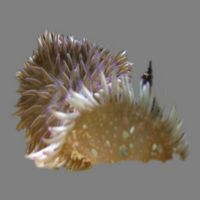
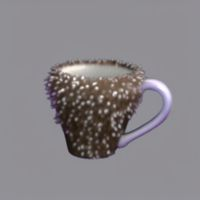
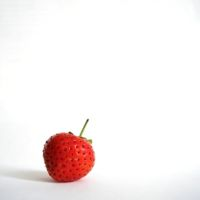
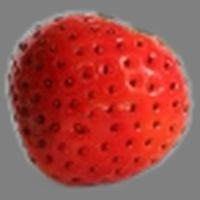
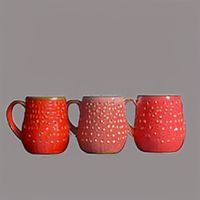
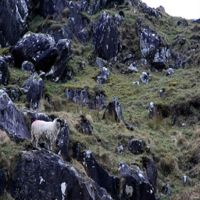
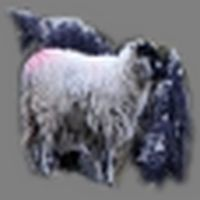
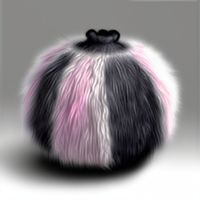
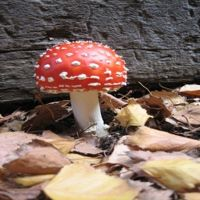
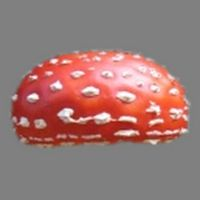
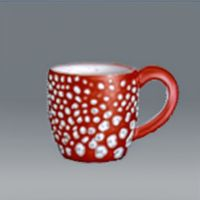
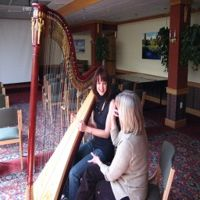
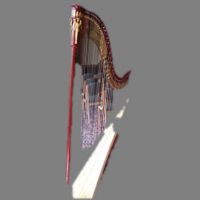
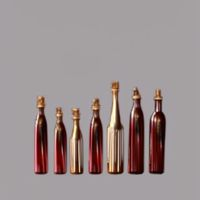
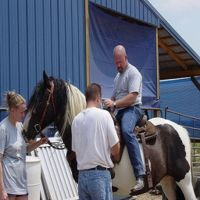
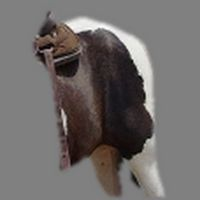
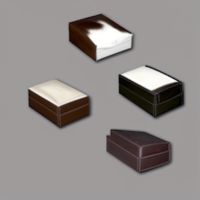
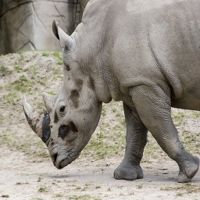
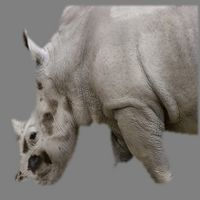
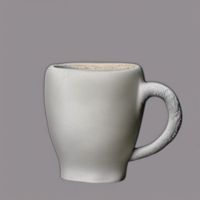
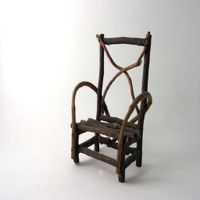
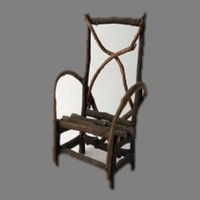
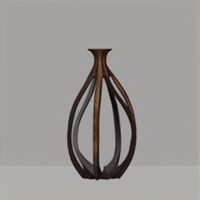
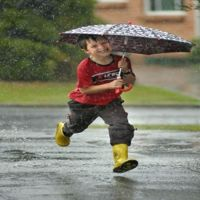
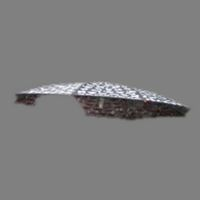
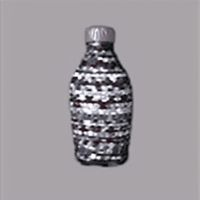
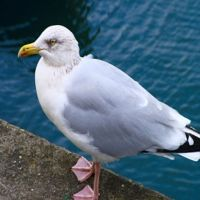
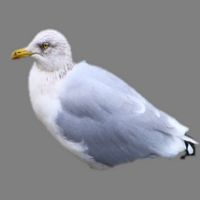
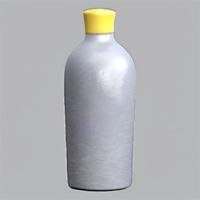
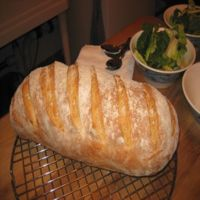
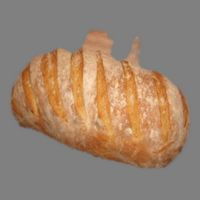
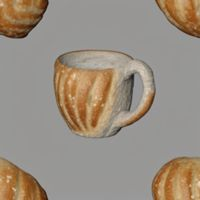

In [16]:
# look at only the failures
show(full[~full.passed], 0, 12)

### Retry failures
Re-runs failed rows with more candidates and fresh seeds, keeping the new result only if it is better. If a row keeps failing and its `seg_method` is `fallback_center`, fix the segmentation for that row (try a different prompt in `cat_name`, or crop it by hand) instead of retrying.

In [17]:
RETRY_CAND = 6
bad = [i for i in full.index[~full.passed]]
for i in tqdm(bad):
    new = process_row(i, stage.loc[i], n_cand=RETRY_CAND, seed_offset=5000)
    old = results[i]
    if new['passed'] or (not old['passed'] and new['color_dist'] + new['dino_sim'] < old['color_dist'] + old['dino_sim']):
        results[i] = new
save_results()

res = pd.DataFrame.from_dict(results, orient='index').sort_index()
final = stage.join(res, how='inner')
final.to_csv(CSV_OUT, index=False)
print('passed:', int(final.passed.sum()), '/', len(final), '| saved ->', CSV_OUT)
backup()
try:
    shutil.copy(CSV_OUT, os.path.join(ROOT, 'sketchy_with_refs_v2.csv'))   # small single file to Drive
except Exception as e:
    print('could not copy the CSV to Drive:', repr(e)[:100])

  0%|          | 0/46 [00:00<?, ?it/s]

passed: 182 / 200 | saved -> /content/ref_v2/sketchy_with_refs_v2.csv
backup saved -> /content/drive/MyDrive/sketchy_dataset_one_sketch/ref_v2_backup.zip
